# Mini-Project 1: Fetching and Displaying a Weather Forecast

This notebook geocodes a place, retrieves and presents an Open-Meteo daily forecast, compares `urllib` with `requests`, checks a second source from MET Norway, and demonstrates robust failure handling.

## Configuration

In [18]:
LOCATION = "Kampala"
CONTACT_EMAIL = "b40815@students.ucu.ac.ug" #Enter a valid university email
CANDIDATE_INDEX = 0
FORECAST_DAYS = 7
RANDOM_SEED = 2026

In [5]:
from pathlib import Path
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    raise RuntimeError("Run this notebook from the repository root.")
sys.path.insert(0, str(ROOT))

from src import weather_api as weather

rng = np.random.default_rng(RANDOM_SEED)
DATA = ROOT / "data"
try:
    import requests as requests_package
    REQUESTS_INSTALLED = True
except ImportError:
    REQUESTS_INSTALLED = False
print(f"requests installed: {REQUESTS_INSTALLED}")

Matplotlib is building the font cache; this may take a moment.


requests installed: True


## Part A - HTTP

Part A implementation constructs the query with `urllib.parse.urlencode`; the second passes a dictionary through `requests.get`. Both report status, content type, elapsed time, and final URL. If the execution environment lacks the dependency or external network, the notebook continues with the saved fixture and clearly reports the fallback.


In [6]:
urllib_result = None
requests_result = None

if REQUESTS_INSTALLED:
    try:
        urllib_result = weather.geocode_urllib(LOCATION, timeout=8)
        requests_result = weather.geocode_requests(LOCATION, timeout=8)
    except weather.WeatherAPIError as exc:
        print(f"Live geocoding unavailable; using fixture. Reason: {exc}")
else:
    print("Install requirements.txt to execute the live requests comparison; using fixture now.")

if urllib_result:
    _, urllib_meta = urllib_result
    print("urllib:", urllib_meta)
if requests_result:
    _, requests_meta = requests_result
    print("requests:", requests_meta)


urllib: RequestMetadata(status_code=200, content_type='application/json; charset=utf-8', elapsed_seconds=1.7675870000384748, url='https://geocoding-api.open-meteo.com/v1/search?name=Kampala&count=10&language=en&format=json')
requests: RequestMetadata(status_code=200, content_type='application/json; charset=utf-8', elapsed_seconds=1.243457100004889, url='https://geocoding-api.open-meteo.com/v1/search?name=Kampala&count=10&language=en&format=json')


### Comparison of `urllib` and `requests`

`urllib` is part of Python's standard library, so it introduces no third-party dependency. It offers detailed control over URL construction, request objects, headers, decoding, and error types.

`requests` is shorter and more readable for common API work. The `params` argument safely encodes the query, `response.json()` performs JSON decoding, `response.raise_for_status()` converts unsuccessful HTTP status codes into exceptions, and the same call accepts headers and timeouts. It also exposes connection pooling through a `Session`.

The trade-off is an external dependency and the need to understand that a request does not time out unless a timeout is supplied.

## Part B - Forecast retrieval and display

In [7]:
if requests_result:
    candidates = requests_result[0]
    source_label = "live Open-Meteo geocoding"
else:
    candidates = weather.load_json(DATA / "geocoding_kampala.json").get("results", [])
    source_label = "saved Open-Meteo sample"

if not candidates:
    raise weather.GeocodingError(f"No location found for {LOCATION!r}")
print(f"Candidates from {source_label}:")
for label in weather.format_candidates(candidates):
    print("  ", label)

selected = weather.choose_location(candidates, CANDIDATE_INDEX)
latitude, longitude = selected["latitude"], selected["longitude"]
print(f"Selected: {selected['name']}, {selected.get('country')} ({latitude}, {longitude})")

Candidates from live Open-Meteo geocoding:
   0: Kampala, Central Region, Uganda
   1: Kampala, Montagnes, Ivory Coast
   2: Kampala, Ituri, Democratic Republic of Congo
   3: Kampala, South Kivu, Democratic Republic of Congo
   4: Kampala, Eastern Province, Zambia
   5: Kampala, South Sulawesi, Indonesia
   6: Kampala, South Sulawesi, Indonesia
   7: Kampala, South Sulawesi, Indonesia
   8: Kampala, South Sulawesi, Indonesia
   9: Kampala, South Sulawesi, Indonesia
Selected: Kampala, Uganda (0.31628, 32.58219)


In [8]:
forecast_payload = None
if REQUESTS_INSTALLED and requests_result:
    try:
        forecast_payload = weather.get_forecast(latitude, longitude, FORECAST_DAYS, timeout=10)
        forecast_source = "Live Open-Meteo"
    except weather.ForecastError as exc:
        print(f"Live forecast unavailable; using saved fixture. Reason: {exc}")

if forecast_payload is None:
    forecast_payload = weather.load_json(DATA / "open_meteo_forecast.json")
    forecast_source = "Saved Open-Meteo sample"

forecast = weather.forecast_to_dataframe(forecast_payload)
print(f"Data source: {forecast_source}. Weather data attribution: Open-Meteo (CC BY 4.0).")
display(forecast.round(1))

Data source: Live Open-Meteo. Weather data attribution: Open-Meteo (CC BY 4.0).


C:\Users\LENOVO THINKPAD\AppData\Local\Temp\ipykernel_7704\551039383.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast.round(1))


,Date,Weather,Maximum temperature (°C),Minimum temperature (°C),Precipitation (mm),Maximum wind speed (km/h)
0,2026-10-11,Thunderstorm,25.1,18.8,17.3,16.0
1,2026-10-12,Moderate rain showers,25.5,18.5,5.0,11.2
2,2026-10-13,Moderate rain showers,26.0,19.7,3.8,12.5
3,2026-10-14,Moderate rain showers,27.3,18.2,4.6,10.1
4,2026-10-15,Moderate drizzle,25.7,19.2,4.5,10.0
5,2026-10-16,Slight rain showers,24.4,18.8,17.7,9.7
6,2026-10-17,Slight rain showers,23.2,18.5,18.3,6.5


In [10]:
max_col = next(c for c in forecast if c.startswith("Maximum temperature"))
min_col = next(c for c in forecast if c.startswith("Minimum temperature"))
rain_col = next(c for c in forecast if c.startswith("Precipitation"))

wettest = forecast.loc[forecast[rain_col].idxmax()]
warmest = forecast.loc[forecast[max_col].idxmax()]
print(
    f"{len(forecast)}-day summary: maximum temperatures range from "
    f"{forecast[max_col].min():.1f}°C to {forecast[max_col].max():.1f}°C. "
    f"The warmest day is {warmest['Date'].date()}; the greatest precipitation "
    f"({wettest[rain_col]:.1f} mm) is forecast for {wettest['Date'].date()}."
)


7-day summary: maximum temperatures range from 23.2°C to 27.3°C. The warmest day is 2026-10-14; the greatest precipitation (18.3 mm) is forecast for 2026-10-17.


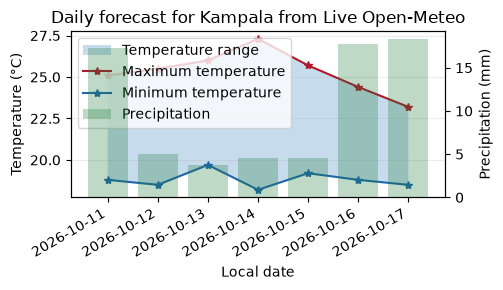

In [17]:
fig, ax_temp = plt.subplots(figsize=(5, 3))
ax_temp.fill_between(forecast["Date"], forecast[min_col], forecast[max_col], alpha=0.25, label="Temperature range")
ax_temp.plot(forecast["Date"], forecast[max_col], marker="*", color="#b2182b", label="Maximum temperature")
ax_temp.plot(forecast["Date"], forecast[min_col], marker="*", color="#2166ac", label="Minimum temperature")
ax_temp.set_ylabel("Temperature (°C)")
ax_temp.set_xlabel("Local date")
ax_temp.grid(axis="y", alpha=0.25)

ax_rain = ax_temp.twinx()
ax_rain.bar(forecast["Date"], forecast[rain_col], alpha=0.28, color="#1b7837", label="Precipitation")
ax_rain.set_ylabel("Precipitation (mm)")

handles1, labels1 = ax_temp.get_legend_handles_labels()
handles2, labels2 = ax_rain.get_legend_handles_labels()
ax_temp.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
ax_temp.set_title(f"Daily forecast for {selected['name']} from {forecast_source}")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Part C - Robustness and a second source

In [19]:
met_payload = None
if REQUESTS_INSTALLED and "YOUR_UNIVERSITY_EMAIL" not in CONTACT_EMAIL:
    try:
        met_payload = weather.met_norway_forecast(latitude, longitude, CONTACT_EMAIL)
        met_source = "Live MET Norway"
    except weather.WeatherAPIError as exc:
        print(f"Live MET Norway request unavailable; using saved fixture. Reason: {exc}")
else:
    print("Enter a valid unversity email since MET live call requires one.")

if met_payload is None:
    met_payload = weather.load_json(DATA / "met_norway_forecast.json")
    met_source = "Saved MET Norway sample"
print(met_source, weather.first_met_observation(met_payload))
print("Attribution: Data from MET Norway (CC BY 4.0 / NLOD 2.0).")


Live MET Norway {'time': '2026-10-11T13:00:00Z', 'air_temperature_c': 24.8, 'wind_speed_m_s': 3.7}
Attribution: Data from MET Norway (CC BY 4.0 / NLOD 2.0).


In [20]:
# 1. Invalid city / absent results
invalid_candidates = weather.load_json(DATA / "geocoding_empty.json").get("results", [])
print("Invalid city -> candidates:", invalid_candidates)

# 2. Invalid latitude
try:
    weather.validate_coordinates(999, 32.5)
except weather.ForecastError as exc:
    print("Invalid latitude ->", exc)

# 3 and 4. Simulated connection loss and tiny-timeout failure
if REQUESTS_INSTALLED:
    class FailingSession:
        def __init__(self, error):
            self.error = error
            self.calls = 0
        def get(self, *args, **kwargs):
            self.calls += 1
            raise self.error

    cases = [
        ("simulated no network", 1.0, requests_package.exceptions.ConnectionError("network disconnected")),
        ("simulated tiny timeout", 0.000001, requests_package.exceptions.Timeout("deadline exceeded")),
    ]
    for label, timeout, error in cases:
        fake = FailingSession(error)
        try:
            weather.request_json("https://example.invalid", timeout=timeout, retries=2, backoff=0, session=fake)
        except weather.WeatherAPIError as exc:
            print(f"{label} -> {fake.calls} attempts -> {exc}")
else:
    print("Failure simulations require requests; the parser tests below still run offline.")


Invalid city -> candidates: []
Invalid latitude -> Latitude must be between -90 and 90 degrees.
simulated no network -> 3 attempts -> Request failed after 3 attempt(s): network disconnected
simulated tiny timeout -> 3 attempts -> Request failed after 3 attempt(s): deadline exceeded


## Offline checks

In [23]:
empty = weather.load_json(DATA / "geocoding_empty.json")
assert empty.get("results", []) == []
assert weather.choose_location(candidates, 0)["name"] == "Kampala"
assert weather.weather_description(95) == "Thunderstorm"
assert len(weather.forecast_to_dataframe(forecast_payload)) == 7
assert "Maximum temperature (°C)" in weather.forecast_to_dataframe(forecast_payload).columns
print("Five offline checks passed.")

Five offline checks passed.


# Part D - Report

## Data flow from a location name to a forecast

The program treats weather retrieval as a sequence of small tasks rather than one large notebook cell. The user supplies a location and contact email in the configuration cell. The location is not yet suitable for a forecast request because the forecast services require geographic coordinates. The geocoding stage therefore sends the place name to Open-Meteo's geocoding endpoint and receives a JSON document containing zero, one, or several candidates. The parser deliberately uses `payload.get("results", [])`, because an unsuccessful search may omit the `results` key instead of returning an empty array.

Ambiguity is preserved. A name such as Springfield may refer to many places, so the program prints numbered labels containing the name, first-level administrative region, and country. `CANDIDATE_INDEX` records the selection in a reproducible way. The selected latitude and longitude are validated before they reach either forecast service. Values outside ±90 degrees latitude or ±180 degrees longitude produce a clear `ForecastError` rather than an opaque remote-service response.

The selected coordinates and requested number of days form the Open-Meteo forecast query. The request explicitly asks for daily maximum and minimum temperature, precipitation sum, maximum wind speed, and weather code. `timezone=auto` is important: without it, daily dates can be aligned to UTC instead of the location's civil date. The JSON arrays are checked for required keys and equal lengths, decoded into human-readable weather descriptions using Open-Meteo's WMO mapping, and placed in a pandas DataFrame. Units from `daily_units` are inserted into the column labels. The final stage derives a short text summary and displays a table and dual-axis chart.

```mermaid
flowchart LR
    A[Location configuration] --> B[Open-Meteo geocoding]
    B --> C[Candidate selection]
    C --> D[Coordinate validation]
    D --> E[Open-Meteo forecast]
    D --> F[MET Norway check]
    E --> G[Validate and parse JSON]
    G --> H[Table, summary and chart]
```

The second source does not attempt a full model-to-model accuracy study. It retrieves the first MET Norway time point and demonstrates that the application can compare independently supplied temperature and wind data. A production comparison would align timestamps, units, spatial grids, and forecast horizons before calculating differences.

## Licensing and usage terms

Open-Meteo's free, open-access API is appropriate for this educational submission but cannot simply be embedded in every commercial product. Its terms, accessed on 7 October 2026, restrict the free service to non-commercial use and publish limits of 600 calls per minute, 5,000 per hour, 10,000 per day, and 300,000 per month. Data are supplied under CC BY 4.0, so an application must provide attribution. A commercial service or one that needs higher limits should use a suitable paid plan rather than assuming that a free classroom endpoint is an unlimited production dependency. Open-Meteo also disclaims guarantees of availability and accuracy, which means a real product needs monitoring, fallbacks, and a user-facing statement about forecast uncertainty.

MET Norway makes its API data available under NLOD 2.0 and CC BY 4.0 and asks users to credit MET Norway. Its service terms add operational obligations. Requests should contain an identifying User-Agent with a genuine way to contact the developer; fake or invented details may lead to blocking. Clients must avoid unnecessary traffic, respect cache headers, use conditional requests, spread scheduled traffic, and keep coordinates to no more than four decimal places. Traffic above 20 requests per second for one application requires an agreement. The service has no delivery guarantee or service-level agreement. For a real product, these terms imply a caching backend, contact and attribution pages, monitoring for 203/429 responses, and a plan for API version changes. The notebook follows the identification and coordinate rules but does not implement a persistent cache because it makes only one low-volume educational request.

## Reliability issues and responses

Remote calls fail for reasons outside the program: DNS or connectivity problems, slow servers, throttling, invalid parameters, server errors, changed schemas, and maintenance. A request without a timeout can wait indefinitely, so every call sets one. A received HTTP response is not automatically a success; `raise_for_status()` converts 4xx and 5xx responses into exceptions. Retrying every error is also wrong. A malformed request that produces 400 will not improve with repetition, while a connection interruption, 429, or 5xx response may be temporary. `request_json()` therefore retries only potentially temporary failures, doubles the delay after each attempt, caps the number of attempts, and converts the final cause into a domain-specific error.

Parsing is protected separately. Required daily arrays must exist and have matching lengths. Unknown weather codes remain visible as unknown instead of being silently mislabeled. Invalid coordinates and forecast-day ranges are rejected locally. Saved geocoding, Open-Meteo, and MET Norway JSON fixtures permit deterministic testing when the internet is absent and also protect the test suite from consuming API capacity. The notebook's fallback makes a classroom demonstration reproducible, but the output announces that it is a saved sample so it cannot be mistaken for a current forecast.

The deliberately broken examples show this behaviour: missing geocoding results become an empty list; latitude 999 is rejected before HTTP; a simulated connection failure is retried only to the cap; and a tiny timeout ends in the same clear exception. In a production system, logging would add request identifiers and timings without recording unnecessary personal location data.

## Privacy implications

A location query can reveal more than a user expects. A city may be low-risk, while precise home, workplace, clinic, or travel coordinates can disclose habits or sensitive circumstances. The weather providers receive the requesting IP address, coordinates, time, and technical headers. Open-Meteo states that free-service logs may contain IP addresses and geographic coordinates and are deleted after 90 days. MET Norway similarly explains that direct client calls expose the user's IP address and coordinates, and recommends a proxy gateway when anonymity matters.

Data minimisation is therefore the first control. The application should ask only for the precision needed by the forecast model, avoid storing search history by default, and explain which third party receives the query. A server-side proxy can prevent the provider from seeing every end user's IP address, centralise caching, enforce rate limits, and remove unnecessary identifiers. The proxy then becomes a data controller in its own right and must be secured, given a retention policy, and prevented from creating a detailed location-history database. Consent and transparency are more meaningful when users can enter a coarse place name rather than being forced to share GPS coordinates.

Finally, the contact email in the MET User-Agent belongs to the application operator, not the weather user. It should be a legitimate institutional, kept in configuration rather than reusable source code, and never replaced with invented details. These controls allow useful forecasts while respecting the principle that a weather query should not silently become a long-lived record of a person's movements.
